# Severity Factors Models 
อุบัติเหตุร้ายแรง ร้ายแรงเพราะปัจจัยใด 

**โจทย์:** ระบุปัจจัยที่ทำให้อุบัติเหตุกลายเป็นอุบัติเหตุร้ายแรง

**ร้ายแรง** หมายถึง มีผู้เสียชีวิตหรือผู้บาดเจ็บสาหัสอย่างน้อย 1 คน

**ต่างจาก notebook `severity_map` อย่างไร:** เล่มนั้นถามว่า "จะร้ายแรงไหม" จึงใช้ได้เฉพาะข้อมูลที่รู้ก่อนเกิดเหตุ เล่มนี้ถามว่า "ร้ายแรงเพราะอะไร" จึงใช้ข้อมูลที่บรรยายตัวเหตุได้ทั้งหมด เช่น มีรถอะไรอยู่ในเหตุ และชนกันแบบไหน ห้ามใช้อย่างเดียวคือจำนวนผู้เสียชีวิตและผู้บาดเจ็บ เพราะนั่นคือคำตอบ

**โมเดลรับอะไร** (หนึ่งแถวคืออุบัติเหตุ 1 ครั้ง)

| ชื่อ | type | ความหมาย |
|---|---|---|
| ปัจจัย 27 ตัว เช่น `มีจักรยานยนต์`, `กลางคืน`, `ชนประสานงา` | int (0 หรือ 1) | 1 คือเหตุนี้มีปัจจัยนั้น |
| `province` | category (78 ค่า) | จังหวัด ใช้คุมความต่างของพื้นที่ |
| `road_type` | category (3 ค่า) | ประเภทถนน ใช้คุมความต่างของหน่วยงานที่บันทึก |

**โมเดลตอบอะไร**

| คำตอบ | type | ตัวอย่าง |
|---|---|---|
| โอกาสร้ายแรงของเหตุนั้น | float (0.0 ถึง 1.0) | 0.71 คือ 71% |
| ปัจจัยแต่ละตัวเพิ่มโอกาสร้ายแรงกี่เท่า (odds ratio) | ตาราง: ชื่อปัจจัย (str), ค่า (float) | `มีจักรยานยนต์` 6.0 เท่า |

**สิ่งที่จะทำ:** อ่านข้อมูล → สำรวจ → คลีน → ดูข้อมูล → สร้างปัจจัย → แบ่งข้อมูล → เลือกโมเดล → ประเมิน → ตอบโจทย์

รันเซลล์จากบนลงล่าง ข้อมูลดิบอยู่ใน `data/datagov/` ส่วนไฟล์ที่ notebook นี้สร้างจะอยู่ใน `data/explore_idea/severity_factors/`

## 1. อ่านข้อมูล
ใช้ข้อมูลอุบัติเหตุทั้งประเทศปี 2563–2569 (ค.ศ. 2020–2026) ปี 2569 มีถึงเดือนตุลาคม

ไม่ใช้ปี 2562 (2019) เพราะไฟล์ปีนั้นไม่มีคอลัมน์ผู้บาดเจ็บสาหัส จึงสร้างคำตอบ "ร้ายแรง" ไม่ได้

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [2]:
# ฟอนต์ที่แสดงภาษาไทยในกราฟได้ (ถ้าเครื่องไม่มี Tahoma ให้เปลี่ยนเป็น "Thonburi" หรือ "Sarabun")
plt.rcParams["font.family"] = "Tahoma"

In [3]:
# notebook นี้อยู่ใน notebooks/explore_idea/ จึงย้อนขึ้นไป 2 ชั้นเพื่อเข้าโฟลเดอร์ data
raw_dir = "../../data/datagov/"
idea_dir = "../../data/explore_idea/severity_factors/"

years = [2020, 2021, 2022, 2023, 2024, 2025, 2026]

In [4]:
# ปี 2026 ตั้งชื่อคอลัมน์บางตัวต่างจากปีอื่น จึงเปลี่ยนชื่อให้ตรงกันก่อนรวม
rename_2026 = {
    "บริเวณที่เกิดเหตุ/ลักษณะทาง": "บริเวณที่เกิดเหตุ",
    "ลักษณะการเกิดอุบัติเหตุ": "ลักษณะการเกิดเหตุ",
    "จำนวนรถที่เกิดเหตุ(รวมคันที่1)": "รถที่เกิดเหตุ",
    "รถบรรทุกมากกว่า6ล้อไม่เกิน10ล้อ": "รถบรรทุกไม่เกิน10ล้อ",
    "รถบรรทุกมากกว่า10ล้อ(รถพ่วง)": "รถบรรทุกมากกว่า10ล้อ",
    "จำนวนผู้เสียชีวิต": "ผู้เสียชีวิต",
    "จำนวนผู้บาดเจ็บสาหัส": "ผู้บาดเจ็บสาหัส",
    "จำนวนผู้บาดเจ็บเล็กน้อย": "ผู้บาดเจ็บเล็กน้อย",
}

frames = []
for year in years:
    table = pd.read_csv(raw_dir + f"accident{year}.csv", dtype=str, encoding="utf-8-sig")
    if year == 2026:
        table = table.rename(columns=rename_2026)
    table["file_year"] = year
    frames.append(table)
    print(year, "จำนวนแถว:", len(table))

# รวมทุกปีเป็นตารางเดียว
raw = pd.concat(frames, ignore_index=True)
print("รวมทั้งหมด:", raw.shape[0], "แถว |", raw.shape[1], "คอลัมน์")

2020 จำนวนแถว: 21239
2021 จำนวนแถว: 20062
2022 จำนวนแถว: 20566
2023 จำนวนแถว: 23841


2024 จำนวนแถว: 23952
2025 จำนวนแถว: 23715
2026 จำนวนแถว: 18448
รวมทั้งหมด: 151823 แถว | 44 คอลัมน์


In [5]:
# เก็บเฉพาะคอลัมน์ที่ใช้ และเปลี่ยนชื่อให้เขียนโค้ดง่าย
column_names = {
    "วันที่เกิดเหตุ": "date_text",
    "เวลา": "time_text",
    "ACC_CODE": "acc_code",
    "สายทางหน่วยงาน": "road_type",
    "รหัสสายทาง": "route_code",
    "จังหวัด": "province",
    "รถคันที่1": "vehicle",
    "บริเวณที่เกิดเหตุ": "area",
    "ลักษณะการเกิดเหตุ": "crash_type_text",
    "มูลเหตุสันนิษฐาน": "cause_text",
    "สภาพอากาศ": "weather",
    "LATITUDE": "lat",
    "LONGITUDE": "lon",
    "รถที่เกิดเหตุ": "n_vehicles",
    "รถจักรยานยนต์": "n_motorcycle",
    "รถบรรทุก6ล้อ": "n_truck6",
    "รถบรรทุกไม่เกิน10ล้อ": "n_truck10",
    "รถบรรทุกมากกว่า10ล้อ": "n_truck10plus",
    "คนเดินเท้า": "n_pedestrian",
    "ผู้เสียชีวิต": "deaths",
    "ผู้บาดเจ็บสาหัส": "serious_injuries",
    "ผู้บาดเจ็บเล็กน้อย": "minor_injuries",
}
selected_columns = ["file_year"] + list(column_names.keys())
data = raw[selected_columns].rename(columns=column_names)
data.head(3)

,file_year,date_text,time_text,acc_code,road_type,route_code,province,vehicle,area,crash_type_text,...,lon,n_vehicles,n_motorcycle,n_truck6,n_truck10,n_truck10plus,n_pedestrian,deaths,serious_injuries,minor_injuries
0,2020,1/1/2020,0:05,3785916,ทางหลวง,4225,กระบี่,คนเดินเท้า,ทางโค้งกว้าง+ไม่มีความลาดชัน,ชนคนเดินเท้า,...,99.39067392,1,0,0,0,0,1,0,1,0
1,2020,1/1/2020,0:05,3786314,ทางหลวง,3473,นครสวรรค์,รถจักรยานยนต์,ทางตรง+ไม่มีความลาดชัน,ชนท้าย,...,99.47842239,2,1,0,0,0,0,0,1,0
2,2020,1/1/2020,0:15,575019,ทางหลวงชนบท,นภ.3038,หนองบัวลำภู,รถจักรยานยนต์,ทางสี่แยก,NaN,...,102.454305,1,1,0,0,0,0,1,0,0


**คอลัมน์ที่เพิ่มจาก notebook `severity_map`**
- `n_vehicles`: จำนวนรถทั้งหมดในเหตุ
- `n_motorcycle`, `n_truck6`, `n_truck10`, `n_truck10plus`: จำนวนรถแต่ละประเภทในเหตุ
- `n_pedestrian`: จำนวนคนเดินเท้าในเหตุ
- `cause_text`: มูลเหตุสันนิษฐานที่เจ้าหน้าที่บันทึก

## 2. สำรวจข้อมูลดิบ
ก่อนคลีน ต้องรู้ก่อนว่าข้อมูลมีปัญหาอะไรบ้าง ดู 4 เรื่อง คือ ค่าว่าง รูปแบบวันที่และเวลา เหตุที่บันทึกซ้ำ และจำนวนหมวดหมู่ของแต่ละปี

In [6]:
# ค่าว่างของแต่ละคอลัมน์ คิดเป็น %
missing_percent = data.isna().mean() * 100
missing_percent.round(1).sort_values(ascending=False)

acc_code            12.2
area                 8.5
crash_type_text      5.6
cause_text           1.9
vehicle              1.5
province             1.3
weather              0.6
lat                  0.6
lon                  0.6
n_truck6             0.0
serious_injuries     0.0
deaths               0.0
n_pedestrian         0.0
n_truck10plus        0.0
n_truck10            0.0
file_year            0.0
n_motorcycle         0.0
n_vehicles           0.0
date_text            0.0
route_code           0.0
road_type            0.0
time_text            0.0
minor_injuries       0.0
dtype: float64

In [7]:
# ดูตัวอย่างวันที่และเวลาของแต่ละปี จะเห็นว่าเขียนไม่เหมือนกัน
for year in years:
    rows = data[data["file_year"] == year]
    example = rows.iloc[500]
    print(year, "| วันที่:", example["date_text"], "| เวลา:", example["time_text"])

2020 | วันที่: 1/3/2020 | เวลา: 14:50
2021 | วันที่: 1/3/2021 | เวลา: 0:10
2022 | วันที่: 02/01/2022 | เวลา: 19:30
2023 | วันที่: 1/2/2023 | เวลา: 20:00
2024 | วันที่: 45294 | เวลา: 0.145833333
2025 | วันที่: 45660 | เวลา: 13:30
2026 | วันที่: 3/1/2026 | เวลา: 4:30


In [8]:
# รหัสเหตุ (acc_code) ที่ซ้ำกันในปีเดียวกัน แปลว่าเหตุเดียวถูกบันทึกมากกว่า 1 แถว
has_code = ~data["acc_code"].isna()
repeated_code = has_code & data.duplicated(subset=["file_year", "acc_code"])
print("จำนวนแถวที่รหัสเหตุซ้ำ แยกตามปี")
print(data[repeated_code]["file_year"].value_counts().sort_index())

จำนวนแถวที่รหัสเหตุซ้ำ แยกตามปี
file_year
2023    1702
Name: count, dtype: int64


In [9]:
# จำนวนคำที่ไม่ซ้ำกันของ "ลักษณะการชน" และ "มูลเหตุ" ในแต่ละปี
unique_count = data.groupby("file_year")[["crash_type_text", "cause_text"]].nunique()
unique_count.columns = ["ลักษณะการชน (จำนวนแบบ)", "มูลเหตุ (จำนวนแบบ)"]
unique_count

,ลักษณะการชน (จำนวนแบบ),มูลเหตุ (จำนวนแบบ)
file_year,,
2020,11,38
2021,10,38
2022,11,48
2023,152,103
2024,10,49
2025,10,47
2026,10,46


**สิ่งที่พบ**
- **ค่าว่าง:** `acc_code` ว่างทั้งปี 2026 เพราะไฟล์ปีนั้นไม่มีรหัสเหตุ ส่วน `area` (ลักษณะถนน) และ `crash_type_text` (ลักษณะการชน) ว่างประมาณ 5–9% จำนวนรถและคนเดินเท้าไม่มีค่าว่าง
- **วันที่:** ปี 2020–2023 เขียนแบบ เดือน/วัน/ปี ปี 2024–2025 เป็นเลขลำดับวันของ Excel เช่น 45540 และปี 2026 เขียนแบบ วัน/เดือน/ปี
- **เวลา:** ปี 2024 เป็นเศษส่วนของวัน เช่น 0.5 หมายถึงเที่ยงวัน ปีอื่นเขียนแบบ ชั่วโมง:นาที
- **เหตุซ้ำ:** ปี 2023 มีรหัสเหตุซ้ำประมาณ 1,700 แถว
- **หมวดหมู่ไม่เหมือนกันทุกปี:** ปี 2023 เขียนลักษณะการชนถึง 152 แบบ ส่วนปีอื่นมีประมาณ 10 แบบ มูลเหตุก็มีหลายสิบแบบและสะกดไม่เหมือนกัน จึงต้องจัดกลุ่มใหม่ด้วยคำสำคัญ ไม่อย่างนั้นโมเดลจะมองว่าเป็นคนละเรื่องกัน

## 3. คลีนข้อมูล
แก้ทีละเรื่องตามที่พบในขั้นสำรวจ แล้วบันทึกผลเป็นไฟล์ใน `clean/`

### 3.1 วันที่
แปลงแยกปี เพราะแต่ละปีเขียนไม่เหมือนกัน

In [10]:
data["date"] = pd.NaT

# ปี 2020–2023 เขียนแบบ เดือน/วัน/ปี เช่น 1/31/2020
rows = data["file_year"] <= 2023
data.loc[rows, "date"] = pd.to_datetime(data.loc[rows, "date_text"], format="%m/%d/%Y", errors="coerce")

# ปี 2024–2025 เป็นเลขลำดับวันของ Excel เช่น 45540 นับจากวันที่ 30 ธ.ค. 1899
rows = (data["file_year"] == 2024) | (data["file_year"] == 2025)
numbers = pd.to_numeric(data.loc[rows, "date_text"], errors="coerce")
data.loc[rows, "date"] = pd.to_datetime(numbers, unit="D", origin="1899-12-30", errors="coerce")

# ปี 2026 เขียนแบบ วัน/เดือน/ปี เช่น 31/1/2026
rows = data["file_year"] == 2026
data.loc[rows, "date"] = pd.to_datetime(data.loc[rows, "date_text"], format="%d/%m/%Y", errors="coerce")

data["date"] = pd.to_datetime(data["date"])

# วันที่ต้องอ่านได้ และต้องอยู่ในปีเดียวกับไฟล์
valid_date = ~data["date"].isna() & (data["date"].dt.year == data["file_year"])
print("แถวที่วันที่ใช้ไม่ได้:", (~valid_date).sum())
data = data[valid_date].copy()

แถวที่วันที่ใช้ไม่ได้: 1


### 3.2 เวลา
เก็บเฉพาะ "ชั่วโมง" (0–23) สำหรับปี 2024 ที่เป็นเศษส่วนของวัน ต้องแปลงเป็นนาทีแล้ว **ปัดเศษ** ก่อน

เหตุผล: เวลา 01:00 ถูกเก็บเป็น 0.041666667 ถ้าเอาไปคูณ 24 ตรง ๆ บางแถวจะได้ 0.99999 แล้วกลายเป็นชั่วโมง 0 ซึ่งผิด

In [11]:
def time_to_hour(text):
    if pd.isna(text):
        return np.nan
    if ":" in text:
        # แบบ ชั่วโมง:นาที เช่น "14:30" ได้ 14
        return int(text.split(":")[0])
    # แบบเศษส่วนของวัน เช่น "0.5" ได้ 720 นาที คือ 12 นาฬิกา
    minutes = round(float(text) * 24 * 60)
    hour = minutes // 60
    if hour > 23:
        hour = 23
    return hour


# ใช้ฟังก์ชันกับทุกแถวของคอลัมน์ time_text
data["hour"] = data["time_text"].apply(time_to_hour)
print("ชั่วโมงต่ำสุด:", data["hour"].min(), "| สูงสุด:", data["hour"].max(), "| ค่าว่าง:", data["hour"].isna().sum())

ชั่วโมงต่ำสุด: 0 | สูงสุด: 23 | ค่าว่าง: 0


### 3.3 เหตุที่บันทึกซ้ำ
ถ้ารหัสเหตุซ้ำกันในปีเดียวกัน เก็บไว้แถวเดียว แล้วลบแถวที่เหมือนกันทุกช่องอีกรอบ (สำหรับปี 2026 ที่ไม่มีรหัสเหตุ)

In [12]:
rows_before = len(data)

# ลบแถวที่รหัสเหตุซ้ำในปีเดียวกัน เก็บไว้แถวแรก
has_code = ~data["acc_code"].isna()
repeated_code = has_code & data.duplicated(subset=["file_year", "acc_code"])
data = data[~repeated_code].copy()

# ลบแถวที่เหมือนกันทุกช่อง (สำหรับปี 2026 ที่ไม่มีรหัสเหตุ)
data = data.drop_duplicates().copy()

print("ก่อนลบ:", rows_before, "แถว | หลังลบ:", len(data), "แถว | ลบไป:", rows_before - len(data))

ก่อนลบ: 151822 แถว | หลังลบ: 150097 แถว | ลบไป: 1725


### 3.4 ตัวเลข และคำตอบ "ร้ายแรง"
แปลงข้อความเป็นตัวเลข แล้วสร้างคอลัมน์ `severe`
- `severe = 1` เมื่อมีผู้เสียชีวิตหรือผู้บาดเจ็บสาหัสอย่างน้อย 1 คน
- `severe = 0` ในกรณีอื่น

In [13]:
number_columns = ["deaths", "serious_injuries", "minor_injuries", "lat", "lon",
                  "n_vehicles", "n_motorcycle", "n_truck6", "n_truck10", "n_truck10plus", "n_pedestrian"]
for column in number_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

count_columns = ["deaths", "serious_injuries", "minor_injuries",
                 "n_vehicles", "n_motorcycle", "n_truck6", "n_truck10", "n_truck10plus", "n_pedestrian"]
print("ค่าว่างของคอลัมน์จำนวน:")
print(data[count_columns].isna().sum())

# ร้ายแรง = มีผู้เสียชีวิตหรือผู้บาดเจ็บสาหัสอย่างน้อย 1 คน
data["severe"] = ((data["deaths"] + data["serious_injuries"]) > 0).astype(int)
print("สัดส่วนเหตุร้ายแรง:", round(data["severe"].mean() * 100, 1), "%")

ค่าว่างของคอลัมน์จำนวน:
deaths              0
serious_injuries    0
minor_injuries      0
n_vehicles          0
n_motorcycle        0
n_truck6            0
n_truck10           0
n_truck10plus       0
n_pedestrian        0
dtype: int64
สัดส่วนเหตุร้ายแรง: 18.5 %


In [14]:
# พิกัดที่อยู่นอกกรอบประเทศไทยถือว่ากรอกผิด เปลี่ยนเป็นค่าว่าง แต่ยังเก็บแถวไว้
in_thailand = (data["lat"] >= 5.5) & (data["lat"] <= 20.6) & (data["lon"] >= 97.2) & (data["lon"] <= 105.8)
print("พิกัดที่ว่างหรืออยู่นอกประเทศไทย:", (~in_thailand).sum(), "แถว")
data.loc[~in_thailand, "lat"] = np.nan
data.loc[~in_thailand, "lon"] = np.nan

พิกัดที่ว่างหรืออยู่นอกประเทศไทย: 869 แถว


### 3.5 ข้อมูลแบบหมวดหมู่
- ตัดช่องว่างหัวท้าย และเติมค่าว่างด้วยคำว่า "ไม่ระบุ"
- จังหวัด "อยุธยา" กับ "พระนครศรีอยุธยา" คือจังหวัดเดียวกัน จึงรวมเป็นชื่อเดียว
- ลักษณะถนน ลักษณะการชน และมูลเหตุ มีหลายสิบถึงร้อยกว่าแบบ จึงจัดเป็นกลุ่มใหญ่ไม่กี่กลุ่มด้วยคำสำคัญ

In [15]:
data["province"] = data["province"].str.strip().replace({"อยุธยา": "พระนครศรีอยุธยา"}).fillna("ไม่ระบุ")
data["weather"] = data["weather"].str.strip().fillna("ไม่ระบุ")
data["road_type"] = data["road_type"].str.strip().fillna("ไม่ระบุ")
data["vehicle"] = data["vehicle"].str.strip().fillna("ไม่ระบุ")

In [16]:
# ลักษณะถนนเขียนเป็น "รูปร่างถนน+ความลาดชัน" เช่น "ทางโค้งกว้าง+ที่ลาดชัน"
def find_road_shape(text):
    if pd.isna(text):
        return "ไม่ระบุ"
    first_part = text.split("+")[0]
    if "โค้ง" in first_part:
        return "ทางโค้ง"
    if "ทางตรง" in first_part:
        return "ทางตรง"
    for word in ["แยก", "วงเวียน", "ทางร่วม", "กลับรถ", "Ramps"]:
        if word in first_part:
            return "ทางแยก"
    if "เชื่อม" in first_part or "เข้า" in first_part:
        return "ทางเชื่อม"
    return "อื่นๆ"


def find_road_slope(text):
    if pd.isna(text) or "+" not in text:
        return "ไม่ระบุ"
    second_part = text.split("+", 1)[1]
    if "ไม่มีความลาดชัน" in second_part or "ที่ราบ" in second_part:
        return "ทางราบ"
    return "ลาดชัน"


data["road_shape"] = data["area"].apply(find_road_shape)
data["road_slope"] = data["area"].apply(find_road_slope)
print(data["road_shape"].value_counts())
print()
print(data["road_slope"].value_counts())

road_shape
ทางตรง       107703
ทางโค้ง       22895
ไม่ระบุ       12784
ทางแยก         3789
ทางเชื่อม      2371
อื่นๆ           555
Name: count, dtype: int64

road_slope
ทางราบ     123438
ไม่ระบุ     19023
ลาดชัน       7636
Name: count, dtype: int64


In [17]:
# จัดลักษณะการชนเป็นกลุ่มใหญ่
def find_crash_type(text):
    if pd.isna(text):
        return "ไม่ระบุ"
    if "คนเดินเท้า" in text:
        return "ชนคนเดินเท้า"
    if "ชนท้าย" in text:
        return "ชนท้าย"
    for word in ["พลิกคว่ำ", "ตกถนน", "เสียหลัก", "เสียการควบคุม", "ล้มเอง"]:
        if word in text:
            return "พลิกคว่ำ/ตกถนน"
    for word in ["ตรงกันข้าม", "ประสานงา", "ฝั่งตรงข้าม"]:
        if word in text:
            return "ชนประสานงา"
    for word in ["สิ่งกีดขวาง", "ชนเกาะ", "ชนป้าย", "จอด"]:
        if word in text:
            return "ชนสิ่งกีดขวาง"
    for word in ["ทางแยก", "เลี้ยว", "ด้านข้าง", "เฉี่ยว", "ทางตรงชน"]:
        if word in text:
            return "ชนด้านข้าง/ทางแยก"
    return "อื่นๆ"


data["crash_type"] = data["crash_type_text"].apply(find_crash_type)
data["crash_type"].value_counts()

crash_type
พลิกคว่ำ/ตกถนน       76140
ชนท้าย               46453
ไม่ระบุ               7635
ชนประสานงา            6611
ชนสิ่งกีดขวาง         6580
อื่นๆ                 3048
ชนด้านข้าง/ทางแยก     2100
ชนคนเดินเท้า          1530
Name: count, dtype: int64

In [18]:
# จัดมูลเหตุสันนิษฐานเป็นกลุ่มใหญ่
def find_cause(text):
    if pd.isna(text):
        return "ไม่ระบุ"
    if "ขับรถเร็ว" in text:
        return "ขับรถเร็ว"
    if "ตัดหน้า" in text:
        return "ตัดหน้ากระชั้นชิด"
    if "หลับใน" in text:
        return "หลับใน"
    if "เมาสุรา" in text or "มึนเมา" in text:
        return "เมาสุรา"
    if "ฝ่าฝืนสัญญาณไฟ" in text:
        return "ฝ่าฝืนสัญญาณไฟ"
    if "แซง" in text:
        return "แซงผิดกฎหมาย"
    if "ย้อนศร" in text:
        return "ขับย้อนศร"
    if "ยาง" in text:
        return "ยางแตก"
    for word in ["อุปกรณ์ยานพาหนะ", "ห้ามล้อ", "เบรคชำรุด"]:
        if word in text:
            return "อุปกรณ์รถบกพร่อง"
    if "ถนนลื่น" in text:
        return "ถนนลื่น"
    return "อื่นๆ"


data["cause"] = data["cause_text"].apply(find_cause)
data["cause"].value_counts()

cause
ขับรถเร็ว            106392
ตัดหน้ากระชั้นชิด     11605
หลับใน                10419
อื่นๆ                  6743
ยางแตก                 2711
อุปกรณ์รถบกพร่อง       2708
ไม่ระบุ                2654
เมาสุรา                2090
ถนนลื่น                1998
ฝ่าฝืนสัญญาณไฟ         1531
แซงผิดกฎหมาย            628
ขับย้อนศร               618
Name: count, dtype: int64

### 3.6 บันทึกข้อมูลที่คลีนแล้ว
หนึ่งแถวคือหนึ่งเหตุ

In [19]:
clean_columns = ["file_year", "date", "hour", "province", "road_type", "vehicle",
                 "weather", "road_shape", "road_slope", "crash_type", "cause",
                 "n_vehicles", "n_motorcycle", "n_truck6", "n_truck10", "n_truck10plus", "n_pedestrian",
                 "lat", "lon", "deaths", "serious_injuries", "minor_injuries", "severe"]
clean = data[clean_columns].rename(columns={"file_year": "year"}).reset_index(drop=True)

clean.to_csv(idea_dir + "clean/accidents_clean.csv", index=False, encoding="utf-8-sig")
print("บันทึกแล้ว: clean/accidents_clean.csv |", len(clean), "แถว")
clean.head(3)

บันทึกแล้ว: clean/accidents_clean.csv | 150097 แถว


,year,date,hour,province,road_type,vehicle,weather,road_shape,road_slope,crash_type,...,n_truck6,n_truck10,n_truck10plus,n_pedestrian,lat,lon,deaths,serious_injuries,minor_injuries,severe
0,2020,2020-01-01,0,กระบี่,ทางหลวง,คนเดินเท้า,แจ่มใส,ทางโค้ง,ทางราบ,ชนคนเดินเท้า,...,0,0,0,1,8.008887,99.390674,0,1,0,1
1,2020,2020-01-01,0,นครสวรรค์,ทางหลวง,รถจักรยานยนต์,แจ่มใส,ทางตรง,ทางราบ,ชนท้าย,...,0,0,0,0,15.650940,99.478422,0,1,0,1
2,2020,2020-01-01,0,หนองบัวลำภู,ทางหลวงชนบท,รถจักรยานยนต์,แจ่มใส,ทางแยก,ไม่ระบุ,ไม่ระบุ,...,0,0,0,0,17.191475,102.454305,1,0,0,1


## 4. ดูข้อมูล
ดู 4 เรื่องที่มีผลกับการสร้างปัจจัยในขั้นถัดไป

### 4.1 เหตุร้ายแรงในแต่ละปี

In [20]:
by_year = clean.groupby("year")["severe"].agg(["count", "mean"])
by_year.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_year.round(3)

,จำนวนเหตุ,สัดส่วนร้ายแรง
year,,
2020,21238,0.220
2021,20062,0.203
2022,20566,0.181
2023,22139,0.176
2024,23952,0.182
2025,23715,0.169
2026,18425,0.168


**อ่านตาราง:** สัดส่วนเหตุร้ายแรงลดลงจาก 22.0% ในปี 2020 เหลือ 16.8% ในปี 2026 ภาพรวมทุกปีอยู่ที่ 18.5% เหตุไม่ร้ายแรงจึงมีมากกว่าประมาณ 4 เท่า

### 4.2 กับดักของคอลัมน์ "รถคันที่ 1"
ข้อมูลมีทั้ง "รถคันที่ 1" (ประเภทรถคันแรกที่บันทึก) และ "จำนวนรถแต่ละประเภทในเหตุ" สองอย่างนี้ให้ภาพไม่เท่ากัน

In [21]:
first_is_motorcycle = clean["vehicle"] == "รถจักรยานยนต์"
any_motorcycle = clean["n_motorcycle"] > 0
hidden_motorcycle = any_motorcycle & ~first_is_motorcycle

print("รถคันที่ 1 เป็นจักรยานยนต์:", round(first_is_motorcycle.mean() * 100, 1), "% ของเหตุทั้งหมด")
print("มีจักรยานยนต์อยู่ในเหตุ:", round(any_motorcycle.mean() * 100, 1), "% ของเหตุทั้งหมด")
print()
print("เหตุที่มีจักรยานยนต์ แต่ไม่ได้เป็นรถคันที่ 1:", hidden_motorcycle.sum(), "เหตุ")
print("สัดส่วนร้ายแรงของเหตุกลุ่มนี้:", round(clean.loc[hidden_motorcycle, "severe"].mean() * 100, 1), "%")
print("สัดส่วนร้ายแรงของเหตุที่ไม่มีจักรยานยนต์เลย:", round(clean.loc[~any_motorcycle, "severe"].mean() * 100, 1), "%")

รถคันที่ 1 เป็นจักรยานยนต์: 14.7 % ของเหตุทั้งหมด
มีจักรยานยนต์อยู่ในเหตุ: 21.4 % ของเหตุทั้งหมด

เหตุที่มีจักรยานยนต์ แต่ไม่ได้เป็นรถคันที่ 1: 10145 เหตุ
สัดส่วนร้ายแรงของเหตุกลุ่มนี้: 45.0 %
สัดส่วนร้ายแรงของเหตุที่ไม่มีจักรยานยนต์เลย: 11.1 %


**อ่านผล:** จักรยานยนต์เป็นรถคันที่ 1 เพียง 14.7% ของเหตุ แต่อยู่ในเหตุจริง 21.4% เหตุที่จักรยานยนต์เป็นคู่กรณีมี 10,145 เหตุ และร้ายแรงถึง 45.0% เทียบกับ 11.1% ของเหตุที่ไม่มีจักรยานยนต์ ถ้าดูแค่รถคันที่ 1 จะมองไม่เห็นเหตุกลุ่มนี้เลย

notebook นี้จึงใช้ "มีรถประเภทนี้อยู่ในเหตุไหม" แทน "รถคันที่ 1 คืออะไร"

### 4.3 มูลเหตุสันนิษฐาน

In [22]:
by_cause = clean.groupby("cause")["severe"].agg(["count", "mean"])
by_cause.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_cause["สัดส่วนของเหตุทั้งหมด"] = by_cause["จำนวนเหตุ"] / len(clean)
by_cause.sort_values("จำนวนเหตุ", ascending=False).round(3)

,จำนวนเหตุ,สัดส่วนร้ายแรง,สัดส่วนของเหตุทั้งหมด
cause,,,
ขับรถเร็ว,106392,0.173,0.709
ตัดหน้ากระชั้นชิด,11605,0.341,0.077
หลับใน,10419,0.159,0.069
อื่นๆ,6743,0.204,0.045
ยางแตก,2711,0.048,0.018
อุปกรณ์รถบกพร่อง,2708,0.098,0.018
ไม่ระบุ,2654,0.013,0.018
เมาสุรา,2090,0.343,0.014
ถนนลื่น,1998,0.085,0.013


**อ่านตาราง:** เจ้าหน้าที่บันทึกมูลเหตุว่า "ขับรถเร็ว" ถึง 70.9% ของเหตุ และเหตุกลุ่มนี้ร้ายแรง 17.3% ซึ่งใกล้กับค่าเฉลี่ย 18.5% คอลัมน์นี้จึงเกือบเป็นค่าเดียวกันทุกแถว และแยกเหตุร้ายแรงได้น้อย

มูลเหตุที่ดูร้ายแรงสูงคือ ขับย้อนศร แซงผิดกฎหมาย เมาสุรา ฝ่าฝืนสัญญาณไฟ และตัดหน้ากระชั้นชิด แต่ยังสรุปไม่ได้ ต้องดูข้อ 4.4 ก่อน

### 4.4 ตัวเลขดิบหลอกตาได้
เหตุที่บันทึกว่า "เมาสุรา" ร้ายแรง 34% ซึ่งสูงกว่าค่าเฉลี่ยเกือบสองเท่า แต่ถ้าแยกดูตามว่ามีจักรยานยนต์ในเหตุไหม ภาพจะเปลี่ยนไป

In [23]:
check = pd.DataFrame({
    "มีจักรยานยนต์": any_motorcycle,
    "เมาสุรา": clean["cause"] == "เมาสุรา",
    "severe": clean["severe"],
})
drunk_table = check.groupby(["มีจักรยานยนต์", "เมาสุรา"])["severe"].agg(["count", "mean"])
drunk_table.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
print(drunk_table.round(3))
print()

drunk = check[check["เมาสุรา"]]
not_drunk = check[~check["เมาสุรา"]]
print("เหตุเมาสุราที่มีจักรยานยนต์:", round(drunk["มีจักรยานยนต์"].mean() * 100, 1), "%")
print("เหตุทั่วไปที่มีจักรยานยนต์:", round(not_drunk["มีจักรยานยนต์"].mean() * 100, 1), "%")

                       จำนวนเหตุ  สัดส่วนร้ายแรง
มีจักรยานยนต์ เมาสุรา                           
False         False       116998           0.110
              True           914           0.211
True          False        31009           0.459
              True          1176           0.445

เหตุเมาสุราที่มีจักรยานยนต์: 56.3 %
เหตุทั่วไปที่มีจักรยานยนต์: 21.0 %


**อ่านตาราง:** เหตุเมาสุรา 56.3% มีจักรยานยนต์อยู่ด้วย ขณะที่เหตุทั่วไปมีเพียง 21.0%

ในกลุ่มที่มีจักรยานยนต์ เหตุเมาสุราร้ายแรง 44.5% ซึ่งไม่ต่างจากเหตุที่ไม่เมา (45.9%) ตัวเลข 34% ของเหตุเมาสุราจึงสูงเพราะมีจักรยานยนต์ปนอยู่มาก ไม่ได้มาจากการเมาอย่างเดียว

ในกลุ่มที่ไม่มีจักรยานยนต์ เหตุเมาสุราร้ายแรง 21.1% สูงกว่าเหตุที่ไม่เมา (11.0%) แต่มีเพียง 914 เหตุ ผลของการเมาจึงมีอยู่ แต่ไม่ชัดเท่าที่ตัวเลข 34% บอก

📌 เรื่องนี้เรียกว่า **confounding** คือปัจจัยสองตัวมาด้วยกัน จนแยกไม่ออกว่าตัวไหนมีผลจริง ถ้าดูทีละปัจจัยจะสรุปผิด

notebook นี้จึงไม่ตอบโจทย์ด้วยตารางสัดส่วนดิบ แต่ใช้โมเดลที่ดูทุกปัจจัยพร้อมกัน เพื่อแยกผลของแต่ละปัจจัยออกจากกัน

## 5. สร้างปัจจัย
แปลงข้อมูลเป็นปัจจัยแบบ "มี" (1) หรือ "ไม่มี" (0) รวม 27 ตัว แบ่งเป็น 5 กลุ่ม

| กลุ่ม | ปัจจัย |
|---|---|
| ใครอยู่ในเหตุ | มีคนเดินเท้า, มีจักรยานยนต์, มีรถบรรทุกใหญ่ (6 ล้อขึ้นไป), จักรยานยนต์กับรถบรรทุกใหญ่, รถ 2 คัน, รถ 3 คันขึ้นไป |
| ชนกันแบบไหน | ชนประสานงา, ชนท้าย, ชนสิ่งกีดขวาง, ชนด้านข้าง/ทางแยก |
| มูลเหตุสันนิษฐาน | ตัดหน้ากระชั้นชิด, หลับใน, เมาสุรา, ฝ่าฝืนสัญญาณไฟ, แซงผิดกฎหมาย, ขับย้อนศร, ยางแตก, อุปกรณ์รถบกพร่อง, ถนนลื่น |
| เมื่อไร | กลางคืน (19:00–04:59), ปีใหม่, สงกรานต์, เสาร์อาทิตย์ |
| สภาพแวดล้อม | ฝนตก, ทางโค้ง, ทางแยก, ทางลาดชัน |

**กรณีอ้างอิง** คือเหตุที่ปัจจัยทุกตัวเป็น 0 ได้แก่ รถคันเดียวพลิกคว่ำหรือตกถนน มูลเหตุขับรถเร็ว ตอนกลางวันของวันธรรมดา อากาศไม่มีฝน บนทางตรงทางราบ ผลของปัจจัยทุกตัวจะเทียบกับกรณีนี้

**ไม่ใช้เป็นปัจจัย:** จำนวนผู้เสียชีวิตและผู้บาดเจ็บ เพราะเป็นคำตอบ

In [24]:
month = clean["date"].dt.month
day = clean["date"].dt.day
heavy_truck_count = clean["n_truck6"] + clean["n_truck10"] + clean["n_truck10plus"]

factors = pd.DataFrame(index=clean.index)

# กลุ่มที่ 1: ใครอยู่ในเหตุ
factors["มีคนเดินเท้า"] = (clean["n_pedestrian"] > 0) | (clean["crash_type"] == "ชนคนเดินเท้า") | (clean["vehicle"] == "คนเดินเท้า")
factors["มีจักรยานยนต์"] = clean["n_motorcycle"] > 0
factors["มีรถบรรทุกใหญ่"] = heavy_truck_count > 0
factors["จักรยานยนต์กับรถบรรทุกใหญ่"] = factors["มีจักรยานยนต์"] & factors["มีรถบรรทุกใหญ่"]
factors["รถ 2 คัน"] = clean["n_vehicles"] == 2
factors["รถ 3 คันขึ้นไป"] = clean["n_vehicles"] >= 3

# กลุ่มที่ 2: ชนกันแบบไหน
factors["ชนประสานงา"] = clean["crash_type"] == "ชนประสานงา"
factors["ชนท้าย"] = clean["crash_type"] == "ชนท้าย"
factors["ชนสิ่งกีดขวาง"] = clean["crash_type"] == "ชนสิ่งกีดขวาง"
factors["ชนด้านข้าง/ทางแยก"] = clean["crash_type"] == "ชนด้านข้าง/ทางแยก"

# กลุ่มที่ 3: มูลเหตุสันนิษฐาน
cause_names = ["ตัดหน้ากระชั้นชิด", "หลับใน", "เมาสุรา", "ฝ่าฝืนสัญญาณไฟ", "แซงผิดกฎหมาย",
               "ขับย้อนศร", "ยางแตก", "อุปกรณ์รถบกพร่อง", "ถนนลื่น"]
for cause_name in cause_names:
    factors[cause_name] = clean["cause"] == cause_name

# กลุ่มที่ 4: เมื่อไร
factors["กลางคืน"] = (clean["hour"] >= 19) | (clean["hour"] <= 4)
factors["ปีใหม่"] = ((month == 12) & (day >= 27)) | ((month == 1) & (day <= 4))
factors["สงกรานต์"] = (month == 4) & (day >= 10) & (day <= 17)
factors["เสาร์อาทิตย์"] = clean["date"].dt.day_of_week >= 5   # 5 = เสาร์, 6 = อาทิตย์

# กลุ่มที่ 5: สภาพแวดล้อม
factors["ฝนตก"] = clean["weather"] == "ฝนตก"
factors["ทางโค้ง"] = clean["road_shape"] == "ทางโค้ง"
factors["ทางแยก"] = clean["road_shape"] == "ทางแยก"
factors["ทางลาดชัน"] = clean["road_slope"] == "ลาดชัน"

# เปลี่ยน True/False เป็น 1/0
factors = factors.astype(int)

factor_names = list(factors.columns)
print("จำนวนปัจจัย:", len(factor_names))
factors.head(3)

จำนวนปัจจัย: 27


,มีคนเดินเท้า,มีจักรยานยนต์,มีรถบรรทุกใหญ่,จักรยานยนต์กับรถบรรทุกใหญ่,รถ 2 คัน,รถ 3 คันขึ้นไป,ชนประสานงา,ชนท้าย,ชนสิ่งกีดขวาง,ชนด้านข้าง/ทางแยก,...,อุปกรณ์รถบกพร่อง,ถนนลื่น,กลางคืน,ปีใหม่,สงกรานต์,เสาร์อาทิตย์,ฝนตก,ทางโค้ง,ทางแยก,ทางลาดชัน
0,1,0,0,0,0,0,0,0,0,0,...,0,0,1,1,0,0,0,1,0,0
1,0,1,0,0,1,0,0,1,0,0,...,0,0,1,1,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,1,1,0,0,0,0,1,0


### 5.1 เหตุร้ายแรงกับเหตุไม่ร้ายแรง มีปัจจัยต่างกันตรงไหน
ดูว่าปัจจัยแต่ละตัวพบในเหตุร้ายแรงกี่ % และพบในเหตุไม่ร้ายแรงกี่ %

In [25]:
severe_rows = factors[clean["severe"] == 1]
other_rows = factors[clean["severe"] == 0]

profile = pd.DataFrame({
    "พบในเหตุร้ายแรง (%)": severe_rows.mean() * 100,
    "พบในเหตุไม่ร้ายแรง (%)": other_rows.mean() * 100,
})
profile["ต่างกัน (เท่า)"] = profile["พบในเหตุร้ายแรง (%)"] / profile["พบในเหตุไม่ร้ายแรง (%)"]
profile = profile.sort_values("ต่างกัน (เท่า)", ascending=False)
profile.round(2)

,พบในเหตุร้ายแรง (%),พบในเหตุไม่ร้ายแรง (%),ต่างกัน (เท่า)
มีคนเดินเท้า,4.55,0.35,12.81
จักรยานยนต์กับรถบรรทุกใหญ่,8.28,0.77,10.71
ขับย้อนศร,1.25,0.22,5.62
มีจักรยานยนต์,53.06,14.24,3.73
ชนประสานงา,10.88,2.93,3.71
แซงผิดกฎหมาย,0.88,0.31,2.81
เมาสุรา,2.57,1.12,2.29
ตัดหน้ากระชั้นชิด,14.22,6.25,2.27
ฝ่าฝืนสัญญาณไฟ,1.82,0.84,2.17
รถ 2 คัน,51.98,30.28,1.72


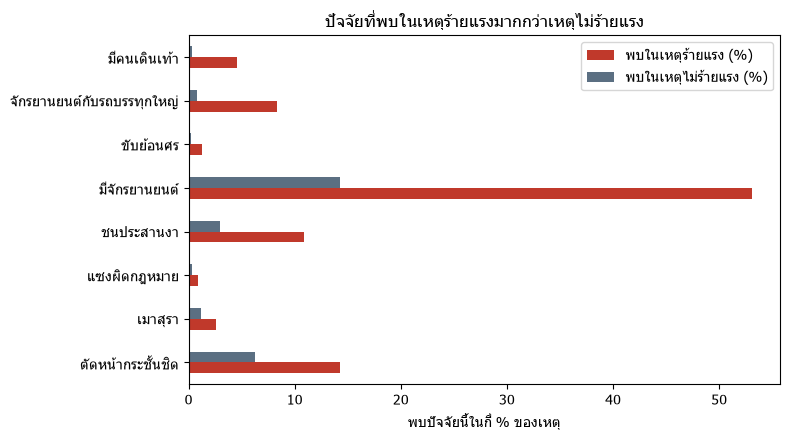

In [26]:
# วาดเฉพาะ 8 ปัจจัยที่ต่างกันมากที่สุด (เรียงจากน้อยไปมาก เพื่อให้ตัวที่ต่างมากที่สุดอยู่บนสุด)
top_profile = profile.head(8).sort_values("ต่างกัน (เท่า)")

top_profile[["พบในเหตุร้ายแรง (%)", "พบในเหตุไม่ร้ายแรง (%)"]].plot.barh(figsize=(8, 4.5), color=["#c0392b", "#5b6f82"])
plt.title("ปัจจัยที่พบในเหตุร้ายแรงมากกว่าเหตุไม่ร้ายแรง")
plt.xlabel("พบปัจจัยนี้ในกี่ % ของเหตุ")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** จักรยานยนต์อยู่ในเหตุร้ายแรง 53.1% แต่อยู่ในเหตุไม่ร้ายแรงเพียง 14.2% เป็นความต่างที่ใหญ่ที่สุดเมื่อนับเป็นจำนวนเหตุ

คนเดินเท้าต่างกันมากที่สุดเมื่อนับเป็นจำนวนเท่า คือ 4.6% กับ 0.4% หรือ 12.8 เท่า แต่พบน้อย ส่วนการชนประสานงาพบ 10.9% กับ 2.9%

ตารางนี้ยังเป็นตัวเลขดิบ จึงยังมีปัญหา confounding แบบข้อ 4.4 ขั้นถัดไปจะใช้โมเดลแยกผลของแต่ละปัจจัย

### 5.2 บันทึกตารางปัจจัย
เพิ่มจังหวัดและประเภทถนนเข้าไปด้วย สองคอลัมน์นี้ไม่ได้เป็นปัจจัยที่จะรายงาน แต่ใส่ให้โมเดลเพื่อ **คุมความต่างของพื้นที่**

เหตุผล: แต่ละจังหวัดและแต่ละหน่วยงานมีสัดส่วนเหตุร้ายแรงต่างกันมาก ส่วนหนึ่งมาจากการบันทึกเหตุเล็กน้อยไม่เท่ากัน ถ้าไม่คุมไว้ ผลของพื้นที่จะปนเข้าไปในปัจจัยอื่น

In [27]:
features = factors.copy()
features["province"] = clean["province"]
features["road_type"] = clean["road_type"]
features["year"] = clean["year"]
features["severe"] = clean["severe"]
print(features.shape)

(150097, 31)


## 6. แบ่งข้อมูล
แบ่งตามเวลา เหมือน notebook `severity_map` เพื่อให้เทียบกันได้
- **Train:** ปี 2020–2023 ใช้ฝึกโมเดล
- **Validation:** ปี 2024 ใช้เลือกโมเดล
- **Test:** ปี 2025–ต.ค. 2026 ใช้ประเมินครั้งสุดท้าย โมเดลไม่เคยเห็นข้อมูลชุดนี้

In [28]:
features["split"] = "test"
features.loc[features["year"] <= 2023, "split"] = "train"
features.loc[features["year"] == 2024, "split"] = "validation"

features.to_csv(idea_dir + "features/accidents_factors.csv", index=False, encoding="utf-8-sig")
print("บันทึกแล้ว: features/accidents_factors.csv")

by_split = features.groupby("split")["severe"].agg(["count", "mean"])
by_split.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_split.round(3)

บันทึกแล้ว: features/accidents_factors.csv


,จำนวนเหตุ,สัดส่วนร้ายแรง
split,,
test,42140,0.169
train,84005,0.195
validation,23952,0.182


## 7. วิธีวัดผล
โจทย์นี้ต้องวัด 2 ชั้น

**ชั้นที่ 1: โมเดลเข้ากับความจริงแค่ไหน** ถ้าโมเดลทำนายไม่ได้ ตัวเลขปัจจัยที่อ่านจากโมเดลก็เชื่อไม่ได้ ใช้ **confusion matrix**

โมเดลตอบเป็นโอกาส (0.0 ถึง 1.0) จึงต้องเลือกเกณฑ์ก่อน ใช้ 30% เท่ากับ notebook `severity_map` คือโอกาสตั้งแต่ 30% ขึ้นไปถือว่า "ร้ายแรง"

| ตัววัด | สูตร | ตอบคำถาม |
|---|---|---|
| **Accuracy** | (TP + TN) ÷ ทั้งหมด | ทายถูกกี่ % ของทั้งหมด |
| **Precision** | TP ÷ (TP + FP) | บอกว่าร้ายแรงแล้วถูกกี่ % |
| **Recall** | TP ÷ (TP + FN) | จากเหตุร้ายแรงทั้งหมด จับได้กี่ % |
| **F1** | 2PR ÷ (P + R) | รวม Precision กับ Recall เป็นตัวเดียว ใช้เลือกโมเดล |

เหตุร้ายแรงมีไม่ถึง 1 ใน 5 ถ้าทายว่า "ไม่ร้ายแรง" ทุกเหตุ จะได้ accuracy เกิน 80% ทั้งที่ไม่มีประโยชน์ จึงดู accuracy อย่างเดียวไม่ได้

**ชั้นที่ 2: ตัวเลขของแต่ละปัจจัยเชื่อได้ไหม** (ทำในหัวข้อ 10)
- **คงที่ข้ามช่วงปี:** ฝึกโมเดลแยกสองช่วงปี แล้วดูว่าได้ค่าใกล้กันไหม

**Baseline:** วิธีง่าย ๆ 2 แบบที่โมเดลต้องชนะ คือทายว่า "ไม่ร้ายแรง" ทุกเหตุ และทายว่า "ร้ายแรง" เมื่อมีจักรยานยนต์อยู่ในเหตุ

In [29]:
threshold = 0.30


def predict_severe(model, x):
    # predict_proba คืนโอกาสของแต่ละคำตอบ คอลัมน์ที่ 1 คือโอกาสที่จะร้ายแรง
    probability = model.predict_proba(x)[:, 1]
    # โอกาสตั้งแต่ 30% ขึ้นไป ถือว่าร้ายแรง (1)
    return (probability >= threshold).astype(int)


def evaluate(name, y_true, y_pred):
    # confusion matrix ของคำตอบ 0/1: [[TN, FP], [FN, TP]]
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn = matrix[0, 0]
    fp = matrix[0, 1]
    fn = matrix[1, 0]
    tp = matrix[1, 1]

    precision = 0
    if tp + fp > 0:
        precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 0
    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)

    return {
        "วิธี": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }

## 8. เลือกโมเดล
ลอง 3 โมเดลกับปัจจัยชุดเดียวกัน แล้ววัดผลบน Validation (ปี 2024)

ทุกโมเดลใช้ข้อมูลชุดเดียวกัน คือปัจจัย 27 ตัวส่งเข้าโมเดลตรง ๆ เพราะเป็น 0/1 อยู่แล้ว ส่วนจังหวัดและประเภทถนนเป็นข้อความ จึงแปลงเป็นคอลัมน์ 0/1 ด้วย `pd.get_dummies` (หนึ่งคอลัมน์ต่อหนึ่งค่า เช่น `province_ชลบุรี`)

In [30]:
# แปลงจังหวัดและประเภทถนนเป็นคอลัมน์ 0/1 ปัจจัย 27 ตัวยังอยู่ลำดับแรกเหมือนเดิม
x_all = pd.get_dummies(features[factor_names + ["province", "road_type"]],
                       columns=["province", "road_type"], dtype=int)
y_all = features["severe"]
print("จำนวนคอลัมน์ที่ส่งเข้าโมเดล:", x_all.shape[1])

train_rows = features["split"] == "train"
validation_rows = features["split"] == "validation"
test_rows = features["split"] == "test"

x_train = x_all[train_rows]
y_train = y_all[train_rows]
x_validation = x_all[validation_rows]
y_validation = y_all[validation_rows]
x_test = x_all[test_rows]
y_test = y_all[test_rows]

จำนวนคอลัมน์ที่ส่งเข้าโมเดล: 108


In [31]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=42),
}

# Baseline 2 แบบ
all_not_severe = [0] * len(y_validation)
motorcycle_rule = x_validation["มีจักรยานยนต์"]

validation_results = []
validation_results.append(evaluate("ทายว่าไม่ร้ายแรงทุกเหตุ", y_validation, all_not_severe))
validation_results.append(evaluate("ทายว่าร้ายแรงเมื่อมีจักรยานยนต์", y_validation, motorcycle_rule))

for name in models:
    model = models[name]
    model.fit(x_train, y_train)
    y_pred = predict_severe(model, x_validation)
    validation_results.append(evaluate(name, y_validation, y_pred))

pd.DataFrame(validation_results).round(3)

,วิธี,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
0,ทายว่าไม่ร้ายแรงทุกเหตุ,19587,0,4365,0,0.818,0.000,0.000,0.000
1,ทายว่าร้ายแรงเมื่อมีจักรยานยนต์,16805,2782,2134,2231,0.795,0.445,0.511,0.476
2,Logistic Regression,17440,2147,1971,2394,0.828,0.527,0.548,0.538
3,Decision Tree,17020,2567,1788,2577,0.818,0.501,0.590,0.542
4,Random Forest,16984,2603,1733,2632,0.819,0.503,0.603,0.548


**อ่านตาราง:**
- **ทายว่าไม่ร้ายแรงทุกเหตุ** ได้ accuracy 81.8% แต่จับเหตุร้ายแรงไม่ได้เลย (Recall 0) ยืนยันว่าดู accuracy อย่างเดียวไม่ได้
- **ทุกโมเดลชนะกฎ "มีจักรยานยนต์"** (F1 0.476) Random Forest ได้ F1 สูงสุด (0.548) ตามด้วย Decision Tree (0.542) และ Logistic Regression (0.538) สามโมเดลต่างกันเพียง 0.01

**เลือก Logistic Regression** แม้ F1 จะไม่สูงที่สุด เหตุผลคือโจทย์ถามว่า "ร้ายแรงเพราะปัจจัยอะไร"
- **Logistic Regression** ให้ตัวเลขหนึ่งตัวต่อหนึ่งปัจจัย อ่านได้ตรง ๆ ว่าปัจจัยนี้เพิ่มโอกาสร้ายแรงกี่เท่า
- **Random Forest** ข้างในเป็นต้นไม้ 100 ต้น จึงบอกไม่ได้ว่าปัจจัยแต่ละตัวทำให้ร้ายแรงขึ้นหรือลดลงกี่เท่า

📌 นี่คือการแลกระหว่าง **ความแม่น** กับ **การอธิบายได้** (accuracy vs interpretability) โจทย์ทำนายควรเลือกตัวที่แม่นที่สุด ส่วนโจทย์อธิบายควรเลือกตัวที่อ่านออก

Random Forest จะถูกใช้อีกครั้งในหัวข้อ 10.3 เพื่อตรวจว่าโมเดลสองแบบเห็นปัจจัยสำคัญตรงกันไหม

## 9. ประเมินบน Test
ฝึกโมเดลใหม่ด้วยปี 2020–2024 แล้ววัดผลกับปี 2025–ต.ค. 2026 ที่โมเดลไม่เคยเห็น

In [32]:
x_train_validation = x_all[train_rows | validation_rows]
y_train_validation = y_all[train_rows | validation_rows]

test_model = LogisticRegression(max_iter=2000)
test_model.fit(x_train_validation, y_train_validation)
test_pred = predict_severe(test_model, x_test)

forest_model = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=42)
forest_model.fit(x_train_validation, y_train_validation)
forest_pred = predict_severe(forest_model, x_test)

test_results = []
test_results.append(evaluate("ทายว่าไม่ร้ายแรงทุกเหตุ", y_test, [0] * len(y_test)))
test_results.append(evaluate("ทายว่าร้ายแรงเมื่อมีจักรยานยนต์", y_test, x_test["มีจักรยานยนต์"]))
test_results.append(evaluate("Logistic Regression (ตัวที่เลือก)", y_test, test_pred))
test_results.append(evaluate("Random Forest (ไว้เทียบ)", y_test, forest_pred))
pd.DataFrame(test_results).round(3)

,วิธี,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
0,ทายว่าไม่ร้ายแรงทุกเหตุ,35034,0,7106,0,0.831,0.000,0.000,0.000
1,ทายว่าร้ายแรงเมื่อมีจักรยานยนต์,30554,4480,3265,3841,0.816,0.462,0.541,0.498
2,Logistic Regression (ตัวที่เลือก),31360,3674,3045,4061,0.841,0.525,0.571,0.547
3,Random Forest (ไว้เทียบ),30881,4153,2652,4454,0.839,0.517,0.627,0.567


**อ่านตาราง:**
- **ชนะวิธีง่าย ๆ:** Logistic Regression ได้ F1 0.547 สูงกว่ากฎ "มีจักรยานยนต์" (0.498) และเมื่อบอกว่าร้ายแรงจะถูก 52.5% ประมาณ 3 เท่าของการชี้แบบสุ่ม ซึ่งจะถูกเท่ากับสัดส่วนเหตุร้ายแรง (16.9%)
- **accuracy หลอกตา:** Logistic Regression ได้ 84.1% สูงกว่าการทายว่าไม่ร้ายแรงทุกเหตุ (83.1%) เพียง 1 จุด ทั้งที่ตัวหลังจับเหตุร้ายแรงไม่ได้เลย
- **ไม่ได้จำข้อมูลปีเก่า:** F1 บน Test (0.547) ใกล้กับ Validation (0.538)
- **ราคาของการอ่านออก:** Random Forest ได้ F1 0.567 สูงกว่า 0.020 เพราะจับเหตุร้ายแรงได้มากกว่า (Recall 62.7% กับ 57.1%) นี่คือสิ่งที่ยอมเสียเพื่อให้อ่านผลของแต่ละปัจจัยได้

### 9.1 ถ้าใช้ตัดสินว่า "ร้ายแรง" หรือ "ไม่ร้ายแรง"
ใช้เกณฑ์ 30% เท่ากับ notebook `severity_map` เพื่อให้เทียบกันได้

In [33]:
print(confusion_matrix(y_test, test_pred))
print()
print(classification_report(y_test, test_pred, target_names=["ไม่ร้ายแรง", "ร้ายแรง"]))

[[31360  3674]
 [ 3045  4061]]

              precision    recall  f1-score   support

  ไม่ร้ายแรง       0.91      0.90      0.90     35034
     ร้ายแรง       0.53      0.57      0.55      7106

    accuracy                           0.84     42140
   macro avg       0.72      0.73      0.73     42140
weighted avg       0.85      0.84      0.84     42140



**อ่านผล:** เหตุร้ายแรงจริง 7,106 เหตุ โมเดลจับได้ 4,061 เหตุ (57.1%) และเมื่อโมเดลบอกว่าร้ายแรง จะถูก 52.5%

ดีกว่า notebook `severity_map` ที่จับได้ 36.9% เพราะเล่มนี้รู้ว่ามีรถอะไรอยู่ในเหตุและชนกันแบบไหน

โมเดลยังพลาดเหตุร้ายแรง 43% จึงยังใช้ตัดสินรายเหตุไม่ได้ แต่โจทย์ของเล่มนี้คือระบุปัจจัย ซึ่งต้องการโมเดลที่เข้ากับข้อมูลพอสมควรและอ่านออก

## 10. คำตอบส่วนที่ 1: ปัจจัยไหนทำให้เหตุร้ายแรง
ฝึก Logistic Regression ด้วยข้อมูลทุกปี แล้วอ่าน **odds ratio** ของแต่ละปัจจัย

📌 **Odds ratio** คือ odds ของเหตุร้ายแรงเพิ่มกี่เท่าเมื่อมีปัจจัยนี้ โดยที่ปัจจัยอื่น จังหวัด และประเภทถนนเหมือนเดิม
- มากกว่า 1 คือปัจจัยนี้ทำให้ร้ายแรงขึ้น
- เท่ากับ 1 คือไม่มีผล
- น้อยกว่า 1 คือปัจจัยนี้มากับเหตุที่ร้ายแรงน้อยลง

**Odds** ไม่ใช่เปอร์เซ็นต์ โอกาส 20% คือ odds 0.25 (20 ต่อ 80) ถ้า odds ratio เป็น 6 จะได้ odds 1.5 ซึ่งคือโอกาส 60%

In [34]:
def get_odds_ratios(model):
    # coef_ คือน้ำหนักของแต่ละคอลัมน์ ปัจจัย 27 ตัวอยู่ลำดับแรก (ก่อนคอลัมน์จังหวัดและประเภทถนน)
    coefficients = model.coef_[0][:len(factor_names)]
    # odds ratio = e ยกกำลังน้ำหนัก
    return pd.Series(np.exp(coefficients), index=factor_names)


final_model = LogisticRegression(max_iter=2000)
final_model.fit(x_all, y_all)

factor_table = pd.DataFrame({
    "พบในเหตุ (%)": factors.mean() * 100,
    "odds ratio": get_odds_ratios(final_model),
})
factor_table.sort_values("odds ratio", ascending=False).round(2)

,พบในเหตุ (%),odds ratio
มีคนเดินเท้า,1.13,24.49
มีจักรยานยนต์,21.44,6.03
จักรยานยนต์กับรถบรรทุกใหญ่,2.16,2.52
รถ 2 คัน,34.30,2.09
ชนประสานงา,4.40,2.01
รถ 3 คันขึ้นไป,7.83,1.74
กลางคืน,34.30,1.49
ชนสิ่งกีดขวาง,4.38,1.25
หลับใน,6.94,1.22
มีรถบรรทุกใหญ่,20.21,1.21


### 10.1 ปัจจัยคงที่ข้ามช่วงปีไหม
ฝึกโมเดลแยกสองช่วง คือปี 2020–2023 และปี 2024–2026 ถ้าปัจจัยมีผลจริง สองช่วงควรได้ค่าใกล้กัน

In [35]:
early_rows = features["year"] <= 2023
late_rows = features["year"] >= 2024

early_model = LogisticRegression(max_iter=2000)
early_model.fit(x_all[early_rows], y_all[early_rows])

late_model = LogisticRegression(max_iter=2000)
late_model.fit(x_all[late_rows], y_all[late_rows])

factor_table["ปี 2020–2023"] = get_odds_ratios(early_model)
factor_table["ปี 2024–2026"] = get_odds_ratios(late_model)

### 10.2 สรุปผลของแต่ละปัจจัย
ตัดสินจากค่า odds ratio 3 ค่า คือจากข้อมูลทุกปี ปี 2020–2023 และปี 2024–2026
- **เพิ่ม:** มากกว่า 1 ทั้ง 3 ค่า
- **ลด:** น้อยกว่า 1 ทั้ง 3 ค่า
- **ไม่ชัด:** กรณีอื่น คือสองช่วงปีให้ทิศทางไม่ตรงกัน

In [36]:
increase = (factor_table["odds ratio"] > 1) & (factor_table["ปี 2020–2023"] > 1) & (factor_table["ปี 2024–2026"] > 1)
decrease = (factor_table["odds ratio"] < 1) & (factor_table["ปี 2020–2023"] < 1) & (factor_table["ปี 2024–2026"] < 1)

factor_table["ผล"] = "ไม่ชัด"
factor_table.loc[increase, "ผล"] = "เพิ่ม"
factor_table.loc[decrease, "ผล"] = "ลด"
factor_table = factor_table.sort_values("odds ratio", ascending=False)

factor_table.to_csv(idea_dir + "results/factor_table.csv", encoding="utf-8-sig", index_label="ปัจจัย")
print("บันทึกแล้ว: results/factor_table.csv")
print(factor_table["ผล"].value_counts())
factor_table.round(2)

บันทึกแล้ว: results/factor_table.csv
ผล
เพิ่ม     14
ลด        10
ไม่ชัด     3
Name: count, dtype: int64


,พบในเหตุ (%),odds ratio,ปี 2020–2023,ปี 2024–2026,ผล
มีคนเดินเท้า,1.13,24.49,20.71,28.87,เพิ่ม
มีจักรยานยนต์,21.44,6.03,5.59,6.82,เพิ่ม
จักรยานยนต์กับรถบรรทุกใหญ่,2.16,2.52,2.52,2.32,เพิ่ม
รถ 2 คัน,34.30,2.09,2.31,1.88,เพิ่ม
ชนประสานงา,4.40,2.01,1.87,2.12,เพิ่ม
รถ 3 คันขึ้นไป,7.83,1.74,1.94,1.56,เพิ่ม
กลางคืน,34.30,1.49,1.54,1.43,เพิ่ม
ชนสิ่งกีดขวาง,4.38,1.25,1.20,1.30,เพิ่ม
หลับใน,6.94,1.22,1.34,1.12,เพิ่ม
มีรถบรรทุกใหญ่,20.21,1.21,1.17,1.30,เพิ่ม


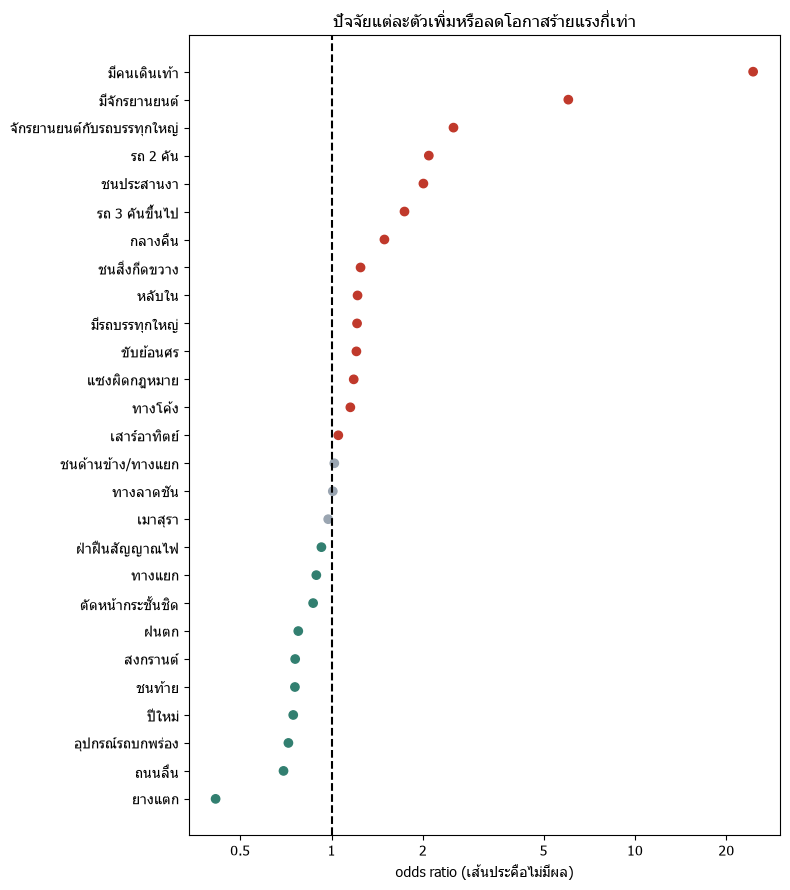

In [37]:
# เรียงจากน้อยไปมาก เพื่อให้ตัวที่ odds ratio สูงที่สุดอยู่บนสุดของกราฟ
chart = factor_table.sort_values("odds ratio")

colors = []
for result in chart["ผล"]:
    if result == "เพิ่ม":
        colors.append("#c0392b")
    elif result == "ลด":
        colors.append("#327f70")
    else:
        colors.append("#9aa5b1")

plt.figure(figsize=(8, 9))
plt.scatter(chart["odds ratio"], chart.index, color=colors)
plt.axvline(1, color="black", linestyle="--")
# ใช้สเกล log เพราะค่าต่างกันมาก (0.4 ถึง 24 เท่า)
plt.xscale("log")
plt.minorticks_off()
plt.xticks([0.5, 1, 2, 5, 10, 20], ["0.5", "1", "2", "5", "10", "20"])
plt.title("ปัจจัยแต่ละตัวเพิ่มหรือลดโอกาสร้ายแรงกี่เท่า")
plt.xlabel("odds ratio (เส้นประคือไม่มีผล)")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** จุดคือ odds ratio สีแดงคือเพิ่ม สีเขียวคือลด สีเทาคือไม่ชัด

**ปัจจัยที่เพิ่มโอกาสร้ายแรง (14 ตัว)**
- **มีคนเดินเท้า:** odds เพิ่ม 24 เท่า สูงที่สุด แต่พบเพียง 1.1% ของเหตุ
- **มีจักรยานยนต์:** 6.0 เท่า และพบถึง 21.4% ของเหตุ
- **จักรยานยนต์กับรถบรรทุกใหญ่:** เพิ่มอีก 2.5 เท่า จากผลของสองปัจจัยนี้รวมกัน
- **รถ 2 คัน** 2.1 เท่า และ **รถ 3 คันขึ้นไป** 1.7 เท่า เทียบกับเหตุรถคันเดียว
- **ชนประสานงา:** 2.0 เท่า เทียบกับพลิกคว่ำหรือตกถนน
- **กลางคืน:** 1.5 เท่า
- **ชนสิ่งกีดขวาง หลับใน มีรถบรรทุกใหญ่ ทางโค้ง:** 1.15–1.25 เท่า
- **ขับย้อนศร** (1.21) และ **แซงผิดกฎหมาย** (1.18): พบเพียง 0.4% ของเหตุ ข้อมูลน้อย ค่าจึงอาจแกว่งได้มาก ควรอ่านอย่างระวัง
- **เสาร์อาทิตย์:** 1.05 เท่า มากกว่า 1 ทุกค่า แต่ผลน้อยมาก

**ปัจจัยที่มากับเหตุร้ายแรงน้อยลง (10 ตัว)**
- **ยางแตก** (0.41) **ถนนลื่น** (0.69) **อุปกรณ์รถบกพร่อง** (0.72): เหตุกลุ่มนี้มักเป็นรถเสียหลักเอง
- **ฝนตก** (0.78): คำอธิบายที่เป็นไปได้คือคนขับช้าลงตอนฝนตก
- **ปีใหม่** (0.75) และ **สงกรานต์** (0.76): ในตารางข้อ 5.1 ปีใหม่พบในเหตุร้ายแรงมากกว่า (10.9% กับ 6.7%) แต่เมื่อคุมปัจจัยอื่นแล้ว เหตุช่วงเทศกาลกลับร้ายแรงน้อยกว่า เพราะตัวเลขดิบสูงจากจักรยานยนต์ที่มีมากขึ้น
- **ตัดหน้ากระชั้นชิด** (0.87): ตัวเลขดิบสูงกว่า 2.3 เท่า แต่เมื่อคุมแล้วกลับต่ำกว่า 1 เป็น confounding แบบเดียวกัน
- **ชนท้าย** (0.76) และ **ทางแยก** (0.89)
- **ฝ่าฝืนสัญญาณไฟ** (0.93): พบเพียง 1.0% ของเหตุ และค่าปี 2020–2023 ใกล้ 1 มาก (0.98) ควรอ่านอย่างระวัง

**ปัจจัยที่ยังไม่ชัด (3 ตัว)**
- **เมาสุรา** (0.97): สองช่วงปีได้ 0.92 กับ 1.02 ตรงกับที่เห็นในข้อ 4.4
- **ชนด้านข้าง/ทางแยก:** สองช่วงปีได้ค่าตรงข้ามกัน (0.80 กับ 1.43) เพราะปี 2023 ใช้ชุดคำต่างจากปีอื่น
- **ทางลาดชัน:** สองช่วงปีได้ 1.03 กับ 0.91

### 10.3 ตรวจซ้ำด้วยโมเดลอีกแบบ
ถ้าปัจจัยสำคัญจริง โมเดลคนละแบบควรเห็นตรงกัน ขั้นนี้ใช้ `feature_importances_` ของ Random Forest ที่ฝึกในหัวข้อ 9

ค่านี้บอกว่า Random Forest ใช้คอลัมน์ไหนแบ่งข้อมูลมากที่สุด ยิ่งสูงยิ่งสำคัญ ค่าทุกคอลัมน์รวมกันได้ 1

In [38]:
importance = pd.Series(forest_model.feature_importances_, index=x_all.columns)
importance = importance.sort_values(ascending=False)

# จังหวัดถูกแยกเป็นหลายคอลัมน์ (หนึ่งคอลัมน์ต่อหนึ่งจังหวัด) จึงรวมคะแนนของทุกจังหวัดเข้าด้วยกัน
province_total = 0
for column in importance.index:
    if column.startswith("province_"):
        province_total = province_total + importance[column]
print("คะแนนรวมของคอลัมน์จังหวัดทั้งหมด:", round(province_total, 3))

importance.head(10).round(3)

คะแนนรวมของคอลัมน์จังหวัดทั้งหมด: 0.213


มีจักรยานยนต์                 0.366
มีคนเดินเท้า                  0.084
จักรยานยนต์กับรถบรรทุกใหญ่    0.067
รถ 2 คัน                      0.061
province_กรุงเทพมหานคร        0.059
ชนประสานงา                    0.040
road_type_ทางหลวงชนบท         0.032
ชนท้าย                        0.021
province_เชียงใหม่            0.021
province_จันทบุรี             0.017
dtype: float64

**อ่านตาราง:** Random Forest ใช้ `มีจักรยานยนต์` มากที่สุด (0.366) ตามด้วยคนเดินเท้า (0.084) จักรยานยนต์กับรถบรรทุกใหญ่ (0.067) รถ 2 คัน (0.061) และชนประสานงา (0.040) ตรงกับปัจจัยอันดับต้นของ Logistic Regression โมเดลสองแบบจึงเห็นตรงกัน

อันดับไม่เหมือนกับ odds ratio ทุกตัว เพราะค่านี้วัดว่าโมเดลใช้คอลัมน์นั้นแบ่งข้อมูลมากแค่ไหน ปัจจัยที่พบบ่อยจึงได้คะแนนสูง คนเดินเท้ามี odds ratio สูงสุดแต่พบน้อย จึงอยู่อันดับสอง

**จังหวัดสำคัญเป็นอันดับสอง** เมื่อรวมทุกจังหวัดได้ 0.213 ทั้งที่ไม่ได้เป็นปัจจัยที่รายงาน แปลว่าเหตุแบบเดียวกันร้ายแรงไม่เท่ากันในแต่ละจังหวัด ข้อมูลนี้แยกไม่ได้ว่ามาจากความอันตรายจริง หรือมาจากการบันทึกเหตุเล็กน้อยไม่เท่ากัน

## 11. สรุป

### สามอย่างที่ต้องมี

| หัวข้อ | คำตอบ |
|---|---|
| **Input feature** | ปัจจัยแบบมีหรือไม่มี 27 ตัว (int 0/1) กับจังหวัดและประเภทถนน (category) ที่ใช้คุมความต่างของพื้นที่ |
| **Model type** | Logistic Regression เพราะให้ตัวเลขหนึ่งตัวต่อหนึ่งปัจจัย |
| **Evaluation metric** | ชั้นที่ 1: confusion matrix (Accuracy, Precision, Recall, F1) บน Test ที่เกณฑ์ 30% ชั้นที่ 2: odds ratio คงที่ข้ามช่วงปีไหม |

### ผลลัพธ์
- **โมเดลเข้ากับความจริงพอใช้:** บน Test จับเหตุร้ายแรงได้ 57.1% (Recall) และบอกว่าร้ายแรงแล้วถูก 52.5% (Precision) ได้ F1 0.547 ชนะกฎ "มีจักรยานยนต์" (0.498)
- **ปัจจัยที่ทำให้ร้ายแรงมากที่สุด:** มีคนเดินเท้า (odds 24 เท่า) มีจักรยานยนต์ (6.0 เท่า) จักรยานยนต์กับรถบรรทุกใหญ่ (เพิ่มอีก 2.5 เท่า) รถ 2 คัน (2.1 เท่า) ชนประสานงา (2.0 เท่า) และกลางคืน (1.5 เท่า)
- **จักรยานยนต์มีผลรวมมากที่สุด:** เพราะทั้งแรงและพบบ่อย Random Forest ก็ใช้ปัจจัยนี้มากที่สุด
- **ตัวเลขดิบหลอกตา:** เมาสุราและช่วงเทศกาลดูร้ายแรงสูง แต่เมื่อคุมปัจจัยอื่นแล้ว เมาสุราไม่ชัด และช่วงเทศกาลกลับร้ายแรงน้อยกว่า
- **สรุปทิศทางได้ 24 จาก 27 ปัจจัย:** เพิ่ม 14 ตัว ลด 10 ตัว และยังไม่ชัด 3 ตัว
- **โมเดลสองแบบเห็นตรงกัน:** Random Forest ให้ปัจจัยอันดับต้นตรงกับ Logistic Regression
- **ใช้ตัดสินรายเหตุไม่ได้:** โมเดลยังพลาดเหตุร้ายแรง 43%

### ข้อจำกัด
- **เป็นความสัมพันธ์ ไม่ใช่การพิสูจน์สาเหตุ:** โมเดลคุมได้เฉพาะสิ่งที่มีในข้อมูล ข้อมูลนี้ไม่มีความเร็วจริง การสวมหมวกกันน็อก และการคาดเข็มขัดนิรภัย
- **มูลเหตุเป็นการสันนิษฐาน:** เจ้าหน้าที่บันทึกหลังเกิดเหตุ และ 71% ถูกบันทึกว่าขับรถเร็ว
- **ปัจจัยที่พบน้อยอาจสรุปผิดทิศ:** ตัดสินจากค่า 3 ค่าเท่านั้น ขับย้อนศร แซงผิดกฎหมาย และฝ่าฝืนสัญญาณไฟ พบไม่ถึง 1% ของเหตุ จึงควรอ่านอย่างระวัง
- **พื้นที่ยังมีผลมาก:** จังหวัดเป็นคอลัมน์ที่โมเดลพึ่งมากเป็นอันดับสอง แต่แยกไม่ได้ว่ามาจากความอันตรายจริงหรือวิธีบันทึกที่ต่างกัน
- **หมวดหมู่ไม่เหมือนกันทุกปี:** ปี 2023 ใช้ชุดคำของลักษณะการชนต่างจากปีอื่น ปัจจัยกลุ่ม "ชนกันแบบไหน" จึงควรอ่านอย่างระวัง